# ДЗ Линейная регрессия

В данном задании мы рассмотрим набор данных об учащихся, собранный в 2006 году в одной из школ Португалии. Данные представлены в неудобном для машинного обучения виде, и содержат мусор. Ваша задача &mdash; привести их к надлежащему виду и обучить на них простую модель.

Данные состоят из четырех файлов:
- data.csv &mdash; основная таблица с информацией о учащихся
- scores.csv &mdash; список финальных оценок по одному из предметов (20-балльная шкала переведенная в проценты)
- attendance.csv &mdash; таблица посещений занятий по этому предмету
- school_support.txt &mdash; список учащихся, которым оказывается финансовая поддержка

Ваша задача &mdash; построить модель для предсказания финальных оценок исходя из всех остальных данных и проверить качество ее работы с помощью кросс-валидации. В качестве алгоритма мы будем использовать линейную регрессию

Расшифровка столбцов в data.csv для справки:
- age &mdash; возраст
- Medu &mdash; уровень образования матери (по некоторой условной шкале)
- Fedu &mdash; уровень образования отца (по некоторой условной шкале)
- traveltime &mdash; время в пути до школы (1 – < 15 мин., 2 – от 15 до 30 мин., 3 – от 30 мин. to 1 ч.
или 4 – > 1 ч.)
- studytime &mdash; время, затрачиваемое на занятия вне школы (1 – < 2 ч., 2 – от 2 до 5 ч., 3 – от 5 до 10 ч. или 4 – > 10 ч.)
- famrel &mdash; насколько хорошие отношения в семье у учащегося (по некоторой условной шкале)
- freetime &mdash; количество свободного времени вне школы (по некоторой условной шкале)
- goout &mdash; время, затрачиваемое на общение с друзьями (по некоторой условной шкале)
- Dalc &mdash; количество употребления алкоголя в учебные дни (по некоторой условной шкале)
- Walc &mdash; количество употребления алкоголя в неучебные дни (по некоторой условной шкале)
- health &mdash; уровень здоровья (по некоторой условной шкале)
- sex_M &mdash; пол: мужской (1) или женский (0)
- address_U &mdash; живет ли учащийся в городе (1) или в пригороде (0)
- famsize_LE3 &mdash; размер семьи: не больше 3 человек (1) или больше (0)
- Pstatus_T &mdash; живут ли родители вместе (1) или отдельно (0)
- nursery &mdash; посещал ли учащийся детский сад
- plans_university &mdash; планирует ли учащийся поступать в университет (-1 или 1)
- past_failures &mdash; количество неудовлетворительных оценок по другим предметам ранее (от 0 до 4)

*Примечание. Несколько признаков в данных содержат ошибки/проблемы/некорректности. Эти проблемы нужно исправить. Для
проверки &mdash; всего в данных таких проблем четыре.*

Начиная с 4 пункта делайте кроссвалидацию на 4 батча до и после, замеряйте результат

### Задача 1: сломанный признак (а может и не один)
__(1 балл)__

Загрузите таблицу data.csv.

Найдите в данных сломанный признак (он не соответствует описанию) и исправьте его.

In [4]:
import pandas as pd

data = pd.read_csv('data.csv')
broken = data['plans_universitypast_failures']
data['plans_university'] = broken.apply(lambda x: 1 if x > 0 else -1)
data['past_failures'] = broken.abs() % 10
data = data.drop(columns=['plans_universitypast_failures'])

data.head()

,age,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,health,sex_M,address_U,famsize_LE3,Pstatus_T,nursery,plans_university,past_failures
0,16,4,4,1,2,5,4,4.0,1.0,2.0,5,1,1,0,1,1,1,0
1,17,4,4,1,1,5,3,4.0,1.0,2.0,5,0,1,0,1,1,1,0
2,16,1,1,2,1,4,5,5.0,2.0,4.0,5,1,0,1,1,1,1,0
3,18,1,2,2,1,3,4,4.0,2.0,4.0,4,1,1,0,1,0,-1,0
4,17,2,1,2,2,4,2,5.0,1.0,2.0,5,0,0,0,1,1,1,0


### Задача 2: пропуски в данных 
__(1 балл)__

Проверьте, есть ли в данных пропуски (значения NaN). Замените все пропущенные значения на среднее значение этого признака по столбцу.

*Hint: изучите в pandas функции loc, isnull, а также передачу булевых массивов в качестве индексов.*

In [7]:
print(data.isnull().sum())
data = data.fillna(data.mean(numeric_only=True))

print(data.isnull().sum())

age                 0
Medu                0
Fedu                0
traveltime          0
studytime           0
famrel              0
freetime            0
goout               0
Dalc                0
Walc                0
health              0
sex_M               0
address_U           0
famsize_LE3         0
Pstatus_T           0
nursery             0
plans_university    0
past_failures       0
dtype: int64
age                 0
Medu                0
Fedu                0
traveltime          0
studytime           0
famrel              0
freetime            0
goout               0
Dalc                0
Walc                0
health              0
sex_M               0
address_U           0
famsize_LE3         0
Pstatus_T           0
nursery             0
plans_university    0
past_failures       0
dtype: int64


### Задача 3: нормализация данных
__(1 балл)__

Нормализуйте данные любым способом, в современных библиотеках нормализация часто встроена внутрь модели, поэтому тут разницы может и не быть в качестве, но сделать надо

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_scaled = pd.DataFrame(
    scaler.fit_transform(data),
    columns=data.columns
)

data_scaled.head()

,age,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,health,sex_M,address_U,famsize_LE3,Pstatus_T,nursery,plans_university,past_failures
0,-0.134205,1.310216,1.540715,-0.275347,0.083653,1.119748,0.780478,0.692772,-0.542692,-0.223769,1.012903,1.199937,0.660182,-0.648175,0.374963,0.495663,0.344914,-0.374305
1,-0.130277,1.310216,1.540715,-0.275347,-1.122808,1.119748,-0.171647,0.692772,-0.542692,-0.223769,1.012903,-0.833377,0.660182,-0.648175,0.374963,0.495663,0.344914,-0.374305
2,-0.134205,-1.336039,-1.188832,0.093107,-1.122808,0.072606,1.732603,1.544607,0.547811,1.340184,1.012903,1.199937,-1.514733,1.542792,0.374963,0.495663,0.344914,-0.374305
3,-0.126349,-1.336039,-0.278983,0.093107,-1.122808,-0.974536,0.780478,0.692772,0.547811,1.340184,0.320930,1.199937,0.660182,-0.648175,0.374963,-2.017502,-2.899275,-0.374305
4,-0.130277,-0.453954,-1.188832,0.093107,0.083653,0.072606,-1.123771,1.544607,-0.542692,-0.223769,1.012903,-0.833377,-1.514733,-0.648175,0.374963,0.495663,0.344914,-0.374305


### Задача 4: кросс-валидация для исходных данных
__(1 балл)__

Загрузите файл scores.csv и протестируйте, как линейная регрессия предсказывает ответ сейчас (с помощью кросс-валидации).

Кроссвалидацию сделайте по 4 разбивкам. Выведите качество в каждом их разбиений.

*Hint: воспользуйтесь sklearn.linear_model и sklearn.model_selection.*

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
import pandas as pd

scores = pd.read_csv('scores.csv', header=None)[0]

model = LinearRegression()
cv_scores = cross_val_score(
    model,
    data_scaled,
    scores,
    cv=4,
    scoring='neg_root_mean_squared_error'
)

rmse_scores = -cv_scores
for i, score in enumerate(rmse_scores, 1):
    print(f'Разбиение {i}: RMSE = {score:.4f}')

print(f'\nСредний RMSE: {rmse_scores.mean():.4f}')

Разбиение 1: RMSE = 13.0723
Разбиение 2: RMSE = 15.5997
Разбиение 3: RMSE = 15.5828
Разбиение 4: RMSE = 15.1580

Средний RMSE: 14.8532


### Задача 5: полные данные
__(2 балла)__

Воспользуйтесь файлами attendance.csv и school_support.txt для того, чтобы добавить новые признаки в данные. Желательно по максимуму использовать возможности pandas для упрощения преобразований.

school_suport число в строке значит что i-ый школьник из исходной таблицы получал мат помощь (обратите внимание что строк в файле меньше, подумайте как правильно импортировать данные)

Добавьте данные таким образом, чтобы качество выросло

In [12]:
attendance = pd.read_csv('attendance.csv', sep=';')
data['attendance_count'] = (attendance == '+').sum(axis=1)
support_students = pd.read_csv('school_support.txt', header=None)[0]

data['school_support'] = 0
data.loc[support_students, 'school_support'] = 1
data_full_scaled = pd.DataFrame(
    scaler.fit_transform(data),
    columns=data.columns
)

cv_scores_full = cross_val_score(
    LinearRegression(),
    data_full_scaled,
    scores,
    cv=4,
    scoring='neg_root_mean_squared_error'
)

rmse_full = -cv_scores_full
for i, score in enumerate(rmse_full, 1):
    print(f'Разбиение {i}: RMSE = {score:.4f}')

print(f'\nСредний RMSE: {rmse_full.mean():.4f}')
print(f'Было: {rmse_scores.mean():.4f}')
print(f'Стало: {rmse_full.mean():.4f}')

Разбиение 1: RMSE = 12.8076
Разбиение 2: RMSE = 15.4010
Разбиение 3: RMSE = 15.8778
Разбиение 4: RMSE = 15.1512

Средний RMSE: 14.8094
Было: 14.8532
Стало: 14.8094


### Задача 6: борьба с выбросами
__(1.5 балла)__

Качество предсказания может ухудшаться, если в данных присутствуют корректные значения признаков (с точки зрения чтения данных и применения методов), но не соответствующие реальным объектам. Например, данные могли быть введены в неверном формате, а потом слишком грубо приведены к общему виду, из-за чего ошибка не была замечена.
Попробуем от такого избавиться &mdash; а для этого такие объекты нужно сначала найти. Конечно, нам еще недоступны многие продвинутые способы, но давайте попробуем обойтись простыми.

Первый способ это сделать &mdash; посмотреть для каждого признака на распределение его значений и проверить крайние значения на правдоподобность. (постройте гистограммы для признаков, как минимум для подозрительных)

*Hint 1: используйте функцию DataFrame.hist*

*Hint 2: в описании датасета выше есть информация, необходимая для восстановления правильных значений*

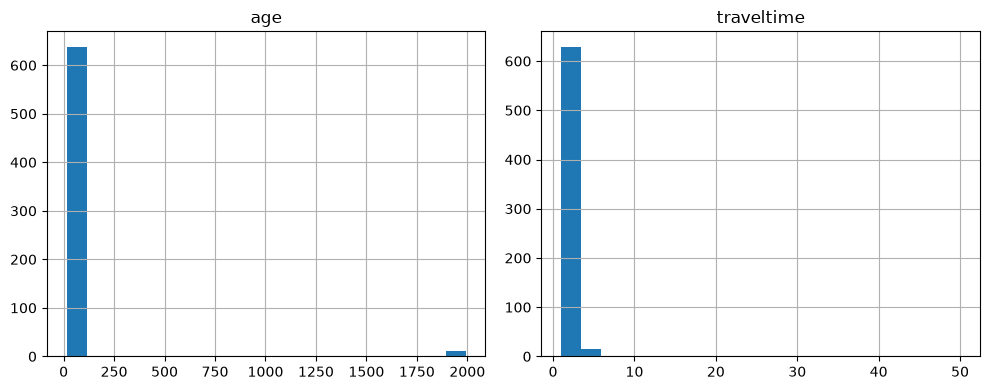

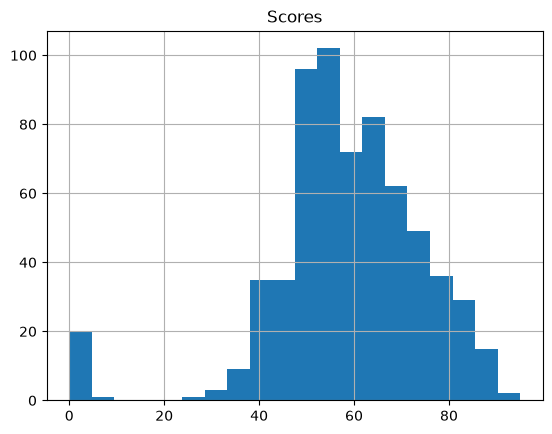

Возраст:
[np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]

Traveltime:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Scores:
[np.float64(0.0), np.float64(5.0), np.float64(25.0), np.float64(30.0), np.float64(35.0), np.float64(40.0), np.float64(45.0), np.float64(50.0), np.float64(55.0), np.float64(55.00000000000001), np.float64(60.0), np.float64(65.0), np.float64(70.0), np.float64(75.0), np.float64(80.0), np.float64(85.0), np.float64(90.0), np.float64(95.0)]


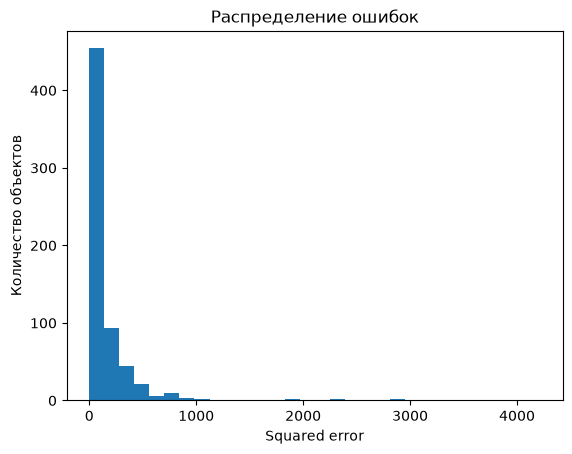

     real_score  prediction  squared_error
354         0.0   64.935446    4216.612139
615         0.0   61.961997    3839.289051
385         0.0   60.779166    3694.107043
319         0.0   59.661752    3559.524608
303         0.0   55.486522    3078.754160
462         0.0   54.179825    2935.453389
423         0.0   53.967606    2912.502486
557         0.0   48.603773    2362.326712
492         0.0   47.892500    2293.691524
501         0.0   46.925946    2202.044370
436         5.0   48.744300    1913.563801
137         0.0   42.826630    1834.120230
287         0.0   42.238172    1784.063195
366         0.0   38.037151    1446.824891
262        80.0   46.106534    1148.767057
481        90.0   56.770638    1104.190517
544        90.0   58.284426    1005.877662
516         0.0   30.775627     947.139222
16         90.0   59.636931     921.915944
118        40.0   69.569624     874.362662
Разбиение 1: RMSE = 12.4953
Разбиение 2: RMSE = 14.0234
Разбиение 3: RMSE = 15.0593
Разбиение 4: 

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

data[['age', 'traveltime']].hist(figsize=(10, 4), bins=20)
plt.tight_layout()
plt.show()
scores.hist(bins=20)
plt.title('Scores')
plt.show()

mask_age = data['age'] > 100
data.loc[mask_age, 'age'] = 2006 - data.loc[mask_age, 'age']

def fix_traveltime(x):
    if x <= 4:
        return x
    elif x < 15:
        return 1
    elif x < 30:
        return 2
    elif x <= 60:
        return 3
    else:
        return 4
data['traveltime'] = data['traveltime'].apply(fix_traveltime)

scores_fixed = scores.copy()
mask_scores = (scores_fixed > 0) & (scores_fixed < 1)
scores_fixed.loc[mask_scores] = scores_fixed.loc[mask_scores] * 100

print('Возраст:')
print(sorted(data['age'].unique()))

print('\nTraveltime:')
print(sorted(data['traveltime'].unique()))

print('\nScores:')
print(sorted(scores_fixed.unique()))

scaler_final = StandardScaler()
data_final_scaled = pd.DataFrame(
    scaler_final.fit_transform(data),
    columns=data.columns
)

regression = LinearRegression()
regression.fit(data_final_scaled, scores_fixed)
prediction = regression.predict(data_final_scaled)
errors = (prediction - scores_fixed.to_numpy()) ** 2

plt.hist(errors, bins=30)
plt.xlabel('Squared error')
plt.ylabel('Количество объектов')
plt.title('Распределение ошибок')
plt.show()

error_table = pd.DataFrame({
    'real_score': scores_fixed,
    'prediction': prediction,
    'squared_error': errors
})
print(
    error_table
    .sort_values('squared_error', ascending=False)
    .head(20)
)


final_cv = cross_val_score(
    LinearRegression(),
    data_final_scaled,
    scores_fixed,
    cv=4,
    scoring='neg_root_mean_squared_error'
)
final_rmse = -final_cv
for i, score in enumerate(final_rmse, 1):
    print(f'Разбиение {i}: RMSE = {score:.4f}')

print(f'\nФинальный средний RMSE: {final_rmse.mean():.4f}')
print(f'После задачи 5: {rmse_full.mean():.4f}')

__(1.5 балла)__

Другой простой способ найти выбросы &mdash; сделать предсказание и посчитать ошибку на каждом объекте по отдельности и посмотреть на объекты с наибольшей ошибкой. Обучите линейную регрессию (функция fit) и для каждого объекта посчитайте среднеквадратичное отклонение. Постройте гистограмму распределения ошибок. Посмотрите на гистограмму и удалите из выборки те объекты на которых ошибка слишком большая.

Обратите внимание, что просто удалять все объекты с высокой ошибкой нельзя &mdash; это, конечно, хороший способ добиться меньшей ошибки (на данной выборке), но одновременно вы ухудшите обобщающую способность алгоритма. Вместо этого вам нужно найти однозначно ошибочные записи и их исправить.

*Hint: возможно, все проблемы уже были найдены первым способом; для проверки &mdash; в сумме здесь нужно исправить 3 проблемы.*

Для поиска ошибки на одном отдельном обьекте придётся обучить линейную регрессию руками. Частичный пример, допишите код. Постройте гистограмму распределения ошибок

In [18]:
from sklearn.linear_model import LinearRegression

regression = LinearRegression()
regression.fit(data_final_scaled, scores_fixed)
prediction = regression.predict(data_final_scaled)
errors = (prediction - scores_fixed.to_numpy()) ** 2

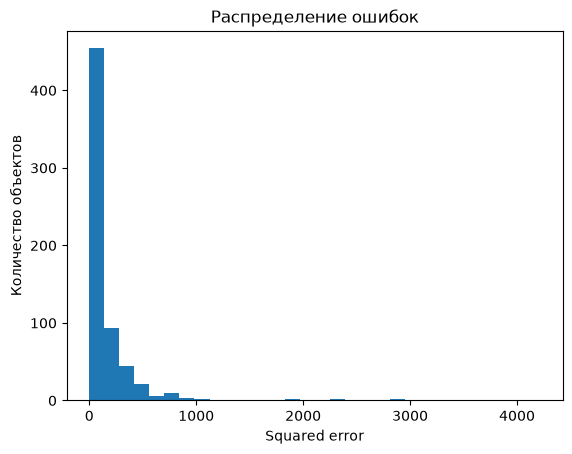

,real_score,prediction,squared_error
354,0.0,64.935446,4216.612139
615,0.0,61.961997,3839.289051
385,0.0,60.779166,3694.107043
319,0.0,59.661752,3559.524608
303,0.0,55.486522,3078.754160
462,0.0,54.179825,2935.453389
423,0.0,53.967606,2912.502486
557,0.0,48.603773,2362.326712
492,0.0,47.892500,2293.691524
501,0.0,46.925946,2202.044370


In [19]:
plt.hist(errors, bins=30)
plt.xlabel('Squared error')
plt.ylabel('Количество объектов')
plt.title('Распределение ошибок')
plt.show()

error_table = pd.DataFrame({
    'real_score': scores_fixed,
    'prediction': prediction,
    'squared_error': errors
})
error_table.sort_values(
    'squared_error',
    ascending=False
).head(20)

### Финальное предсказание и отчёт (1 балл)

Проведите предсказание еще раз и сравните качество с исходным. Запишите свои наблюдения - как изменялось качество обучения модели при использовании разных модификаций данных. 

In [17]:
final_cv = cross_val_score(
    LinearRegression(),
    data_final_scaled,
    scores_fixed,
    cv=4,
    scoring='neg_root_mean_squared_error'
)

final_rmse = -final_cv

for i, score in enumerate(final_rmse, 1):
    print(f'Разбиение {i}: RMSE = {score:.4f}')

print('\nСравнение качества:')
print(f'Исходные данные: {rmse_scores.mean():.4f}')
print(f'После добавления новых признаков: {rmse_full.mean():.4f}')
print(f'После исправления выбросов: {final_rmse.mean():.4f}')

Разбиение 1: RMSE = 12.4953
Разбиение 2: RMSE = 14.0234
Разбиение 3: RMSE = 15.0593
Разбиение 4: RMSE = 14.3557

Сравнение качества:
Исходные данные: 14.8532
После добавления новых признаков: 14.8094
После исправления выбросов: 13.9834


### Отчёт

В ходе работы данные были последовательно подготовлены для обучения линейной регрессии.

Сначала был восстановлен сломанный признак `plans_universitypast_failures`, который был разделён на два отдельных признака: `plans_university` и `past_failures`. Затем пропущенные значения были заменены средними значениями соответствующих признаков, после чего данные были нормализованы.

На исходном наборе данных средний RMSE при кросс-валидации на 4 разбиениях составил примерно **14.85**.

После добавления информации о посещаемости занятий и материальной поддержке учащихся средний RMSE уменьшился до примерно **14.81**, то есть качество модели немного улучшилось.

Далее были найдены и исправлены некорректные значения в данных: возраст, время в пути до школы и некоторые значения итоговых оценок. После исправления этих ошибок средний RMSE снизился примерно до **13.98**.

Таким образом, последовательная очистка данных и добавление новых признаков улучшили качество линейной регрессии. Итоговая ошибка стала меньше исходной примерно на **0.87 RMSE**.